In [1]:
import pandas as pd
import re, sys, os, glob, shutil
import numpy as np
from tqdm import tqdm
from typing import List, Dict, Any, Optional
sys.path.insert(0, '..')
from edautils.qchem import mk_qchem_eda_input
from edautils.qchem import parse_qchem_eda_output

pistack_dir = os.getcwd()

# Convert Frag to XYZ

In [2]:
def row2xyz(row, xyz, comment):
    """
    Convert row of Dataframe to XYZ file
    
    Parameters
    ----------
    row: pd.Series object
        Must have a column called 'xyz' containing 3D coordinates
        and a column 'elements' containing atom symbols
    xyz: os.PathLike
        The path to the written XYZ file
    comment: Any
        The comment line in the xyz file
    """
    
    fp = open(xyz, 'w')
    xyz = row['xyz'].split()
    elements = row['elements'].split()
    fp.write(f'{len(elements)}\n{comment}\n')
    for i in range(len(elements)):
        fp.write(f"{elements[i]} {xyz[i*3]} {xyz[i*3+1]} {xyz[i*3+2]}\n")        
    fp.close()

In [3]:
eda_dir = os.path.join(pistack_dir, 'pi_stack_EDA')
os.chdir(pistack_dir)

df = pd.read_csv('pi_stacks_center.csv', index_col=0)
df

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
3q2m_49_PHE_769-778_1-11,3q2m,3q2m_CKI_A_400,pdbbind_opt_sm/,49,PHE,A,1,UNL,Z,769 770 772 774 776 778,...,29.612,35.590,25.0,0.0,CNS(=O)(=O)C1=C2C=NC=CC2=C(Cl)C=C1,12.0,0.0,C1=CC=CC=C1,C N C C C Cl C C C C C S O O N C H H H H H H H...,-2.499 25.721 34.953 -3.755 25.354 34.458 -4.2...
6xrl_588_TRP_9671-9677_7-32,6xrl,6xrl_V7Y_A_1101,biolip2_opt/,588,TRP,A,1,UNL,Z,9671 9673 9674 9675 9676 9677,...,14.296,-19.294,36.0,0.0,CC#CC1=CC=CC2=C1C(=O)N(C1=CC=CC=C1)C(C)=C2,16.0,0.0,C1=CC2=C(C=C1)NC=C2,C C C C C C C C C C C C C C C N C C O C C H H ...,-17.838 19.622 -14.639 -18.725 18.691 -15.273 ...
3r35_55_HIS_900-907_51-57,3r35,3r35_4CO_B_170,biolip2_opt/,55,HIS,A,1,UNL,Z,900 901 903 905 907,...,41.393,18.688,18.0,0.0,CC(=O)C1=CC=C(O)C=C1,9.0,0.0,C1=CNC=N1,O C C C C C O C C C H H H H H H H H C N H C H ...,70.049 45.095 18.898 69.552 46.043 19.496 68.2...
2vcg_716_PHE_10614-10623_1-7,2vcg,2vcg_S17_A_1378,pdbbind_opt_sm/,716,PHE,D,1,UNL,Z,10614 10615 10617 10619 10621 10623,...,-5.671,37.154,15.0,0.0,CC1=CC=C(Br)C=C1,12.0,0.0,C1=CC=CC=C1,C C C Br C C C C H H H H H H H C C H C H C H C...,-7.920 -4.719 34.118 -8.387 -3.772 35.020 -8.7...
6hsk_140_PHE_2148-2157_3-14,6hsk,6hsk_GOK_A_404,pdbbind_opt_sm/,140,PHE,A,1,UNL,Z,2148 2149 2151 2153 2155 2157,...,9.136,-14.915,23.0,0.0,CN(C)C1=NC=C(C(=O)NO)C=N1,12.0,0.0,C1=CC=CC=C1,N O C C C C N C C O N C N H H H H H H H H H H ...,-16.183 6.788 -9.417 -17.879 7.976 -10.280 -15...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4y6d_86_TYR_1358-1367_11-17,4y6d,4y6d_48U_A_301,biolip2_opt/,86,TYR,A,1,UNL,Z,1358 1359 1361 1363 1365 1367,...,5.836,16.081,32.0,0.0,CC(=O)N(C)C1=C(F)C=C(C(=O)N(C)C)C=C1,13.0,0.0,OC1=CC=CC=C1,C N C C O C C C F C C C N C O C C H H H H H H ...,10.330 1.112 18.311 9.447 1.258 17.142 9.735 0...
6moz_314_TYR_4904-4913_9-17,6moz,6moz_JXA_A_517,biolip2_opt/,314,TYR,A,1,UNL,Z,4904 4905 4907 4909 4911 4913,...,328.369,-2.908,21.0,0.0,CN1C=C(C2=CC=CC=C2)N=N1,13.0,0.0,OC1=CC=CC=C1,C C C C C C C C C N N N H H H H H H H H H C C ...,7.099 325.340 -4.541 5.943 325.098 -3.812 6.95...
4x61_316_PHE_5142-5151_1-23,4x61,4x61_3XV_A_702,pdbbind_opt_sm/,316,PHE,A,1,UNL,Z,5142 5143 5145 5147 5149 5151,...,-46.944,-8.546,22.0,0.0,CNC(=O)C1=CC(NC)=NC=N1,12.0,0.0,C1=CC=CC=C1,C C C C C N C O N N N C H H H H H H H H H H C ...,22.651 -51.858 -9.455 21.938 -50.284 -11.090 2...
5akg_336_TRP_5253-5263_6-10,5akg,5akg_6N6_A_1550,pdbbind_opt_sm/,336,TRP,A,1,UNL,Z,5253 5256 5257 5259 5261 5263,...,13.406,22.815,16.0,0.0,NC1=NN=C(C2=CC=CS2)S1,16.0,0.0,C1=CC2=C(C=C1)NC=C2,C C C S C C N N C S N H H H H H C C H C N H C ...,12.630 12.839 26.981 13.613 11.968 26.541 13.2...


In [4]:
if not os.path.isdir(eda_dir):
    os.mkdir(eda_dir)
    
os.chdir(eda_dir)

for index, row in df.iterrows():
    interaction = os.path.join(eda_dir, index)
    
    if not os.path.isdir(interaction):
        os.mkdir(interaction)

    xyzdir = os.path.join(interaction, 'struct.xyz')
    row2xyz(row, xyzdir, index)

# Generate Input

In [5]:
def generate_fragments(row):
    natoms0 = int(row['natoms0'])
    natoms1 = int(row['natoms1'])
    elements = row['elements'].split()
    xyz = row['xyz'].split()
    xyz = list(map(float, xyz))
    xyz = [xyz[coord * 3:(coord + 1) * 3] for coord in range(len(elements))]
    atoms = [elements[:natoms0], elements[-natoms1:]]
    coords = [xyz[:natoms0], xyz[-natoms1:]]
    charges = [int(row['charge0']), int(row['charge1'])]
    return atoms, coords, charges

In [6]:
names = ['fragment1', 'fragment2']

for interaction in glob.glob('*'):
    edain = os.path.join(interaction, 'eda.in')
    xyz = os.path.join(interaction, 'struct.xyz')
    fp = open(xyz, 'r')
    for i, line in enumerate(fp):
        if i == 1:
            index = line.strip()
    fp.close()
    atoms, coords, charges = generate_fragments(df.loc[index])
    mk_qchem_eda_input(atoms, coords, charges, names, edain)

(array([  2.,   6.,   7.,  41.,  52.,  88.,  60., 124., 114., 109., 102.,
         74.,  40.,  50.,  52.,  22.,  18.,  19.,   6.,   7.,   3.,   0.,
          3.,   0.,   1.]),
 array([18.  , 19.84, 21.68, 23.52, 25.36, 27.2 , 29.04, 30.88, 32.72,
        34.56, 36.4 , 38.24, 40.08, 41.92, 43.76, 45.6 , 47.44, 49.28,
        51.12, 52.96, 54.8 , 56.64, 58.48, 60.32, 62.16, 64.  ]),
 <BarContainer object of 25 artists>)

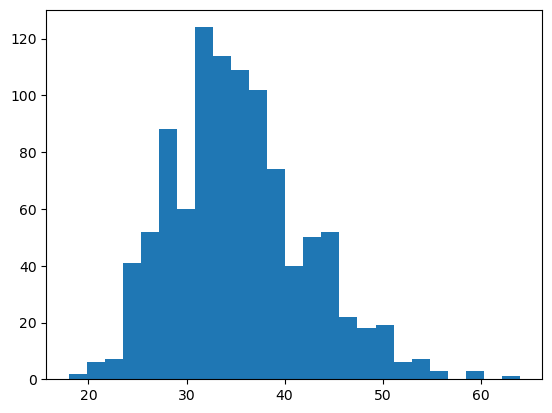

In [31]:
import numpy as np
import matplotlib.pyplot as plt

natomss = []

for index, row in df.iterrows():
    natoms0 = int(row['natoms0'])
    natoms1 = int(row['natoms1'])
    natomss.append(natoms0+natoms1)

fig, ax = plt.subplots()
ax.hist(natomss, bins=25)

# Generate output

In [2]:
os.chdir(pistack_dir)
df = pd.read_csv('pi_stacks_center.csv', index_col=0)

In [3]:
dfEDA = pd.DataFrame()

errs = []

for interaction in tqdm(glob.glob('pi_stack_EDA/*/')):
    done = os.path.join(interaction, 'done.tag')
    out = os.path.join(interaction, 'eda.out')
    xyz = os.path.join(interaction, 'struct.xyz')
    try: 
        fp = open(xyz, 'r')
        for i, line in enumerate(fp):
            if i == 1:
                index = line.strip()
        fp.close()
        # index = os.path.basename(os.path.normpath(interaction))
        series = df.loc[index]
        seriesEDA = pd.Series(parse_qchem_eda_output(out))
        seriesEDA = pd.concat([series, seriesEDA])
        seriesEDA.name = index
        dfEDA = pd.concat([dfEDA, seriesEDA.to_frame().T])
    except Exception as e:
        # raise e
        errs.append((e, index))

print(errs)

dfEDA.rename(columns={'Unnamed: 0': ''}, inplace=True)
dfEDA.to_csv('pi_stack_EDA.csv')

dfEDA

100%|██████████| 1000/1000 [00:01<00:00, 770.18it/s]

[]


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,PAULI,DISP,CLS_ELEC,MOD_PAULI,CLS_DISP,PREPARATION,FROZEN,POLARIZATION,CHARGE_TRANSFER,TOTAL
3t19_231_TRP_3830-3843_12-17,3t19,3t19_5MA_A_561,pdbbind_opt_sm/,231,TRP,A,1,UNL,Z,3830 3831 3833 3834 3836 3837 3839 3841 3843,...,49.6546,-28.1272,-12.7813,29.3947,NaN,0.0,-11.5138,-2.6237,-3.7063,-17.8438
5lkr_757_TRP_11846-11859_2-7,5lkr,5lkr_6YC_B_611,pdbbind_opt_sm/,757,TRP,B,1,UNL,Z,11846 11847 11849 11850 11852 11853 11855 1185...,...,21.265,-16.1241,-5.9109,12.5846,NaN,-0.0,-9.4504,-1.3915,-2.1749,-13.0167
2oqi_629_TYR_10130-10139_7-27,2oqi,2oqi_GGO_B_901,pdbbind_opt_sm/,629,TYR,B,1,UNL,Z,10130 10131 10133 10135 10137 10139,...,20.9196,-15.362,-2.8244,11.5765,NaN,0.0,-6.6099,-1.3825,-1.8063,-9.7987
3r6t_142_TRP_2266-2279_28-32,3r6t,3r6t_LU1_A_307,pdbbind_opt_sm/,142,TRP,A,1,UNL,Z,2266 2267 2269 2270 2272 2273 2275 2277 2279,...,77.0697,-35.0285,-11.5011,45.9564,NaN,0.0,-0.5732,-4.8675,-4.781,-10.2217
4pg3_746_HIS_12207-12214_3-9,4pg3,4pg3_KRS_D_602,pdbbind_opt_sm/,746,HIS,D,1,UNL,Z,12207 12208 12210 12212 12214,...,46.9351,-20.0991,-10.922,32.4816,NaN,0.0,1.4604,-2.1902,-4.3733,-5.103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6h12_119_TYR_1926-1935_15-46,6h12,6h12_FJK_B_619,pdbbind_opt_sm/,119,TYR,B,1,UNL,Z,1926 1927 1929 1931 1933 1935,...,121.9437,-28.112,-30.8906,76.9962,NaN,-0.0,17.9936,-12.5863,-13.2766,-7.8693
3uuo_581_PHE_9405-9410_1-20,3uuo,3uuo_0CV_B_1,pdbbind_opt_sm/,581,PHE,B,1,UNL,Z,9405 9406 9407 9408 9409 9410,...,55.6763,-43.7783,-6.0995,30.8768,NaN,0.0,-19.001,-1.9611,-3.6242,-24.5863
4zph_507_TRP_8199-8205_5-14,4zph,4zph_PRL_A_501,pdbbind_opt_sm/,507,TRP,B,1,UNL,Z,8199 8200 8202 8203 8205,...,11.8516,-22.926,-1.9803,4.8568,NaN,-0.0,-20.0494,-1.3352,-1.4919,-22.8766
2vvu_206_TRP_3228-3241_5-10,2vvu,2vvu_H22_A_1244,pdbbind_opt_sm/,206,TRP,A,1,UNL,Z,3228 3229 3231 3232 3234 3235 3237 3239 3241,...,59.5435,-35.7245,-20.1723,37.3615,NaN,0.0,-18.5353,-4.6194,-5.8222,-28.9768


# PLIP RING Aromaticity Validation

In [4]:
from edautils.fragment import find_rings_old
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

processed_df = dfEDA.copy()

dataset_dir = '../dataset'
hetratom_lig = []
aromatic_lig = []

hetrato_atoms = []
aromatic_atoms = []

errs = []

for index, row in processed_df.iterrows():
    aromatic = True
    temp_atomlist = []
    ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    ring_list = find_rings_old(mol, find_hetero_rings=False, find_small_rings=False) # only aromatic rings, idx numbers in OpenBabel 1 lower than Plip

    lig_idx_list = row['lig_idx_list'].split()
    lig_idx_set = set([int(id) - 1 for id in lig_idx_list])
    ring_temp = [s for s in ring_list if lig_idx_set & s]
     
    if row['PDBID'] == '3b2q': # 3b2q_129_PHE_1993-2002_15-21 marked as Parallel : reclassify as T-shaped interaction with [21, 22, 23, 24, 25, 27, 28, 29, 30]? 
        ring_temp = [{21, 22, 23, 24, 25, 27, 28, 29, 30}]
        row['type'] = 'T'
    elif row['PDBID'] == '2cm8': # 2cm8_182_PHE_3018-3027_1-5 flagged non aromatic ring : reclassify as parallel wtih phenol group [8, 9, 10, 11, 12, 13] ?
        ring_temp = [{8, 9, 10, 11, 12, 13}] 
        row['type'] = 'P'
    
    try:
        for idx in ring_temp[0]:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
            if not symbol == 'C':
                aromatic = False

        if aromatic:
            aromatic_lig.append(index)
            aromatic_atoms.append((index, temp_atomlist)) # keep the list of atoms
        else:
            hetratom_lig.append(index)
            hetrato_atoms.append((index, temp_atomlist)) # keep the list of atoms
    except Exception as e:
        for idx in lig_idx_set:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
        print(index, lig_idx_set, ring_list)
        errs.append(index)

print(len(errs))

3atw_42_HIS_692-698_23-28 {22, 23, 24, 25, 26, 27} [{32, 33, 34, 35, 31}]
2hwi_478_TYR_7442-7451_13-17 {12, 13, 14, 15, 16} [{0, 1, 2, 3, 4, 5}, {19, 20, 21, 22, 23}]
1o86_485_TYR_7828-7837_24-28 {23, 24, 25, 26, 27} [{6, 7, 8, 9, 10, 11}]
6dgr_244_HIS_3965-3972_4-22 {3, 4, 15, 16, 21} [{0, 1, 11, 12, 13, 14}, {20, 5, 6, 7, 8}]
6dgl_59_PHE_978-987_8-30 {7, 8, 22, 24, 29} [{0, 16, 17, 13, 14, 15}, {3, 4, 5, 6, 19, 20}, {23, 25, 10, 11, 12}]
2hha_629_TYR_10134-10143_4-16 {3, 4, 5, 6, 15} [{20, 9, 10, 11, 12, 13}, {17, 18, 19, 7, 8}]
3wtm_186_TYR_2926-2935_7-14 {6, 9, 11, 12, 13} [{1, 2, 3, 4, 7, 8}]
5oh7_166_TRP_2563-2573_2-6 {1, 2, 3, 4, 5} []
4bj8_212_TRP_3179-3192_11-16 {10, 11, 12, 14, 15} []
2ovh_99_PHE_1649-1658_11-17 {10, 11, 12, 14, 15, 16} [{22, 23, 24, 25, 29, 30}]
5oha_69_TRP_1065-1071_2-6 {1, 2, 3, 4, 5} []
2bgd_183_PHE_3049-3058_2-8 {1, 2, 3, 6, 7} [{8, 9, 10, 11, 12, 13}, {16, 17, 18, 19, 20, 21}]
3wth_55_TRP_896-906_9-13 {8, 9, 10, 11, 12} [{0, 1, 2, 4, 5, 6}]
5ov9_285_HIS

In [5]:
rows = processed_df.loc[errs, ['smiles0']]
mols = [Chem.MolFromSmiles(s) for s in rows['smiles0']]
legends = [str(idx) for idx in rows.index]

# Draw.MolsToGridImage(mols, legends=legends,subImgSize=(300, 300),molsPerRow=5)

In [6]:
processed_df["group"] = pd.NA
processed_df["prot_hetero"] = pd.NA
processed_df["lig_hetero"] = pd.NA


hetratom_prot = []
aromatic_prot = []

for index, row in processed_df.iterrows():
    if row['restype'] == 'TYR' or row['restype'] == 'PHE':
        aromatic_prot.append(index)
    else:
        hetratom_prot.append(index)


for index, row in processed_df.iterrows():
    if index in hetratom_prot and index in hetratom_lig:
        processed_df.loc[index, "group"] = "Heterocyclic"
    elif index in aromatic_lig and index in aromatic_lig:
        processed_df.loc[index, "group"] = "Carbocyclic"
    else:
        processed_df.loc[index, "group"] = "Mixed"


for index, row in processed_df.iterrows():
    if index in errs:
        print(index)
        continue
    if index in hetratom_prot:
        processed_df.loc[index, "prot_hetero"] = True
    else:
        processed_df.loc[index, "prot_hetero"] = False
    
    if index in hetratom_lig:
        processed_df.loc[index, "lig_hetero"] = True
    else:
        processed_df.loc[index, "lig_hetero"] = False    
    
    if index in hetratom_prot and index in hetratom_lig:
        processed_df.loc[index, "group"] = "Heterocyclic"
    elif index in aromatic_lig and index in aromatic_lig:
        processed_df.loc[index, "group"] = "Carbocyclic"
    else:
        processed_df.loc[index, "group"] = "Mixed"

processed_df = processed_df.drop(errs)
processed_df.to_csv('pi_stack_EDA.csv')
processed_df

3atw_42_HIS_692-698_23-28
2hwi_478_TYR_7442-7451_13-17
1o86_485_TYR_7828-7837_24-28
6dgr_244_HIS_3965-3972_4-22
6dgl_59_PHE_978-987_8-30
2hha_629_TYR_10134-10143_4-16
3wtm_186_TYR_2926-2935_7-14
5oh7_166_TRP_2563-2573_2-6
4bj8_212_TRP_3179-3192_11-16
2ovh_99_PHE_1649-1658_11-17
5oha_69_TRP_1065-1071_2-6
2bgd_183_PHE_3049-3058_2-8
3wth_55_TRP_896-906_9-13
5ov9_285_HIS_4334-4341_8-13
5oh2_172_TRP_2668-2674_2-6
4dve_161_PHE_2469-2478_11-16
2nta_182_PHE_3025-3034_8-17
1j37_486_TYR_7871-7880_7-14
5oh9_187_TRP_2865-2871_2-6
2xgm_392_TYR_5958-5967_2-10
4o43_423_HIS_6912-6919_5-11
3dux_71_HIS_1176-1183_12-18


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,MOD_PAULI,CLS_DISP,PREPARATION,FROZEN,POLARIZATION,CHARGE_TRANSFER,TOTAL,group,prot_hetero,lig_hetero
3t19_231_TRP_3830-3843_12-17,3t19,3t19_5MA_A_561,pdbbind_opt_sm/,231,TRP,A,1,UNL,Z,3830 3831 3833 3834 3836 3837 3839 3841 3843,...,29.3947,NaN,0.0,-11.5138,-2.6237,-3.7063,-17.8438,Carbocyclic,True,False
5lkr_757_TRP_11846-11859_2-7,5lkr,5lkr_6YC_B_611,pdbbind_opt_sm/,757,TRP,B,1,UNL,Z,11846 11847 11849 11850 11852 11853 11855 1185...,...,12.5846,NaN,-0.0,-9.4504,-1.3915,-2.1749,-13.0167,Carbocyclic,True,False
2oqi_629_TYR_10130-10139_7-27,2oqi,2oqi_GGO_B_901,pdbbind_opt_sm/,629,TYR,B,1,UNL,Z,10130 10131 10133 10135 10137 10139,...,11.5765,NaN,0.0,-6.6099,-1.3825,-1.8063,-9.7987,Carbocyclic,False,False
3r6t_142_TRP_2266-2279_28-32,3r6t,3r6t_LU1_A_307,pdbbind_opt_sm/,142,TRP,A,1,UNL,Z,2266 2267 2269 2270 2272 2273 2275 2277 2279,...,45.9564,NaN,0.0,-0.5732,-4.8675,-4.781,-10.2217,Heterocyclic,True,True
4pg3_746_HIS_12207-12214_3-9,4pg3,4pg3_KRS_D_602,pdbbind_opt_sm/,746,HIS,D,1,UNL,Z,12207 12208 12210 12212 12214,...,32.4816,NaN,0.0,1.4604,-2.1902,-4.3733,-5.103,Carbocyclic,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6h12_119_TYR_1926-1935_15-46,6h12,6h12_FJK_B_619,pdbbind_opt_sm/,119,TYR,B,1,UNL,Z,1926 1927 1929 1931 1933 1935,...,76.9962,NaN,-0.0,17.9936,-12.5863,-13.2766,-7.8693,Mixed,False,True
3uuo_581_PHE_9405-9410_1-20,3uuo,3uuo_0CV_B_1,pdbbind_opt_sm/,581,PHE,B,1,UNL,Z,9405 9406 9407 9408 9409 9410,...,30.8768,NaN,0.0,-19.001,-1.9611,-3.6242,-24.5863,Mixed,False,True
4zph_507_TRP_8199-8205_5-14,4zph,4zph_PRL_A_501,pdbbind_opt_sm/,507,TRP,B,1,UNL,Z,8199 8200 8202 8203 8205,...,4.8568,NaN,-0.0,-20.0494,-1.3352,-1.4919,-22.8766,Heterocyclic,True,True
2vvu_206_TRP_3228-3241_5-10,2vvu,2vvu_H22_A_1244,pdbbind_opt_sm/,206,TRP,A,1,UNL,Z,3228 3229 3231 3232 3234 3235 3237 3239 3241,...,37.3615,NaN,0.0,-18.5353,-4.6194,-5.8222,-28.9768,Heterocyclic,True,True


# Copy Fragment to EDA directory

In [3]:
dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
errs = []

dfEDA = pd.read_csv("pi_stack_EDA.csv", index_col=0)

for index, row in tqdm(dfEDA.iterrows(), total=len(dfEDA)):
    try:
        protfrag = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackProteinFragment/{index}.pdb")
        ligfrag = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackLigandFragment/{index}.sdf")
        edadir = os.path.join(pistack_dir, f"pi_stack_EDA/{index}/")

        shutil.copy(protfrag, edadir)
        shutil.copy(ligfrag, edadir)

        if os.path.exists(os.path.join(edadir, f"{index}.pdb")):
            os.rename(os.path.join(edadir, f"{index}.pdb"), os.path.join(edadir, "ProtFragment.pdb"))
        if os.path.exists(os.path.join(edadir, f"{index}.sdf")):
            os.rename(os.path.join(edadir, f"{index}.sdf"), os.path.join(edadir, "LigFragment.sdf"))
    except Exception as e:
        errs.append((index, e))



100%|██████████| 1000/1000 [00:01<00:00, 808.23it/s]
